# Critical difference diagrams for the benchmark

Read saved results in `results/` and compare **average ranks across datasets**, with one Nemenyi critical difference (CD) diagram per metric. No training or metric recomputation is performed.

Run all cells from the repository root or `scripts/`. Requires NumPy, pandas, SciPy, Matplotlib (already in `requirements.txt`), and a Jupyter Python kernel. Edit the settings below to choose metrics, models, datasets, or result directories. Figures and audit tables are exported to `results/critical_difference/`.

Current selection: **Cora, CiteSeer, and PolBlogs**, with the 12 models listed in `MODELS`. Short names `arga`, `gae`, `vgae`, and `kmeans` resolve to `arga_kmeans`, `gae_kmeans`, `vgae_kmeans`, and `kmeans_attributes` in the saved CSVs. Canonical IDs are also accepted.

In [9]:
from pathlib import Path
from datetime import datetime, timezone
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import friedmanchisquare, studentized_range
from IPython.display import display, Markdown


def find_repo_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "benchmark_comparison.py").is_file() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError("Run this notebook from the repository root or scripts/.")


ROOT = find_repo_root()
if str(ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(ROOT / "scripts"))
from benchmark_comparison import MODEL_NAMES, METRIC_NAMES, METRIC_DIRECTIONS

RESULTS_ROOT = ROOT / "results"
RESULT_PATHS = None  # None: discover immediate result directories; or ["results/cora_benchmark_adaptive", ...].
METRICS = ["nmi", "ari", "acc", "f1_macro"]
MODELS = ["arga", "gae", "vgae", "coane", "dgcss", "dmon", "dsagc", "kmeans", "node2vec_kmeans", "sanece", "soli", "densgnn"]
DATASETS = ["cora", "citeseer", "polblogs"]
# Short names accepted in MODELS; CSV identifiers remain unchanged.
MODEL_ALIASES = {
    "arga": "arga_kmeans",
    "gae": "gae_kmeans",
    "vgae": "vgae_kmeans",
    "kmeans": "kmeans_attributes",
}
EXCLUDE_MODELS = []  # Optional explicit exclusions, never selected by performance.
MIN_VALID_RUNS = 1  # Raise to 5 to require at least five finite, successful seeds per cell.
MIN_DATASETS_PER_MODEL = 2  # Coverage filter, used only when MODELS is None.
ALPHA = 0.05
HIGHLIGHT_MODEL = "densgnn"
EXPORT_DIR = RESULTS_ROOT / "critical_difference"
SAVE_EXPORTS = True
# Optional overrides by source directory name; useful for experiments with custom names.
# {"custom_folder": {"dataset": "cora", "models": {"densgnn": "densgnn_custom"}}}
SOURCE_OVERRIDES = {}

if not 0 < ALPHA < 1:
    raise ValueError("ALPHA must be between 0 and 1.")
if MIN_VALID_RUNS < 1 or MIN_DATASETS_PER_MODEL < 2:
    raise ValueError("MIN_VALID_RUNS >= 1 and MIN_DATASETS_PER_MODEL >= 2 are required.")
if not METRICS or len(set(METRICS)) != len(METRICS):
    raise ValueError("Choose a nonempty list of distinct metrics.")
for metric in METRICS:
    if METRIC_DIRECTIONS.get(metric) not in {"higher", "lower"}:
        raise ValueError(f"No optimization direction for {metric!r}; n_clusters is descriptive, not a ranking metric.")
for name, values in (("MODELS", MODELS), ("DATASETS", DATASETS)):
    if values is not None and (isinstance(values, str) or not values or len(set(values)) != len(values)):
        raise ValueError(f"{name} must be None or a nonempty list of distinct IDs.")
if MODELS is not None:
    resolved_models = [MODEL_ALIASES.get(model, model) for model in MODELS]
    if len(set(resolved_models)) != len(resolved_models):
        raise ValueError("MODELS contains duplicate methods after resolving aliases.")
    print("Selected models (CSV IDs):", ", ".join(resolved_models))
SNAPSHOT_TIME = datetime.now(timezone.utc).isoformat()
print(f"Results: {RESULTS_ROOT}\nSnapshot (UTC): {SNAPSHOT_TIME}")

Selected models (CSV IDs): arga_kmeans, gae_kmeans, vgae_kmeans, coane, dgcss, dmon, dsagc, kmeans_attributes, node2vec_kmeans, sanece, soli, densgnn
Results: /home/gmessias/NodeClusteringAlgorithms/results
Snapshot (UTC): 2026-10-24T20:08:57.067318+00:00


## Read and audit the saved runs

For each immediate result directory, prefer `runs/*/metrics.csv`; use the dataset-level `metrics.csv` only if no per-run CSV exists. This avoids counting aggregate and per-run copies twice. Exported analysis tables are not read recursively.

The repository's `*_benchmark_adaptive` names map to the underlying dataset name. Separate `*_core`/`*_border` directories map `densgnn` to `densgnn_core`/`densgnn_border` on that same dataset. Use `SOURCE_OVERRIDES` for other naming schemes. Multiple sources for the same dataset/model are rejected to avoid silently mixing different experiments.

Only `status=success` contributes scores. Repeated dataset/model/seed attempts retain the latest successful attempt (by timestamp-based `run_id`), or latest failed attempt if none succeeded. Missing seeds use `run_id` instead. Failed attempts, discarded retries, invalid files, and the number of finite runs remain visible; failures never become zeros.

In [10]:
def source_spec(source):
    name = source.name
    spec = {"dataset": name.removesuffix("_benchmark_adaptive"), "models": {}}
    for variant in ("core", "border"):
        if name.endswith(f"_{variant}"):
            spec = {"dataset": name.removesuffix(f"_{variant}"),
                    "models": {"densgnn": f"densgnn_{variant}"}}
    spec.update(SOURCE_OVERRIDES.get(name, {}))
    return spec


def load_results():
    sources = sorted(RESULTS_ROOT.iterdir()) if RESULT_PATHS is None else [
        (Path(p) if Path(p).is_absolute() else ROOT / p).resolve() for p in RESULT_PATHS
    ]
    parts, inventory, issues = [], [], []
    seen = set()
    for source in sources:
        source = source.resolve()
        if source in seen or source == EXPORT_DIR.resolve():
            continue
        seen.add(source)
        if not source.is_dir():
            if RESULT_PATHS is not None:
                issues.append({"path": str(source), "error": "Result directory not found"})
            continue
        files = sorted((source / "runs").glob("*/metrics.csv"))
        layout = "per-run"
        if not files and (source / "metrics.csv").is_file():
            files, layout = [source / "metrics.csv"], "aggregate"
        if not files:
            continue
        spec = source_spec(source)
        loaded = 0
        for path in files:
            try:
                frame = pd.read_csv(path, skipinitialspace=True)
                if frame.empty or not {"model", "status"}.issubset(frame):
                    raise ValueError("Empty CSV or missing model/status columns")
                for column in ("model", "status"):
                    if frame[column].isna().any() or frame[column].astype(str).str.strip().eq("").any():
                        raise ValueError(f"Missing {column} identifier")
                    frame[column] = frame[column].astype(str).str.strip()
                frame["status"] = frame["status"].str.lower()
                if "dataset" in frame and frame["dataset"].dropna().astype(str).str.strip().ne(source.name).any():
                    raise ValueError("Saved dataset differs from source directory; inspect before combining experiments")
                frame["dataset"] = spec["dataset"]
                frame["model"] = frame["model"].replace(spec["models"])
                if "run_id" not in frame:
                    if layout == "aggregate":
                        raise ValueError("Aggregate CSV needs run_id to distinguish trials")
                    frame["run_id"] = path.parent.name
                frame["run_id"] = frame["run_id"].fillna(path.parent.name).astype(str)
                seed = pd.to_numeric(frame.get("seed", pd.Series(np.nan, index=frame.index)), errors="coerce")
                if (seed.notna() & (~np.isfinite(seed) | seed.mod(1).ne(0))).any():
                    raise ValueError("Seeds must be finite integers or missing")
                frame["seed"] = seed.astype("Int64")
                frame["source"] = str(source.relative_to(ROOT)) if source.is_relative_to(ROOT) else str(source)
                frame["metrics_file"] = str(path)
                for metric in METRICS:
                    frame[metric] = pd.to_numeric(frame.get(metric, np.nan), errors="coerce")
                    frame[metric] = frame[metric].replace([np.inf, -np.inf], np.nan)
                parts.append(frame)
                loaded += 1
            except (OSError, ValueError, pd.errors.ParserError) as exc:
                issues.append({"path": str(path), "error": str(exc)})
        inventory.append({"source": str(source), "dataset": spec["dataset"],
                          "layout": layout, "files": len(files), "loaded": loaded})
    if not parts:
        raise ValueError(f"No readable results. Check RESULT_PATHS. Details: {issues}")
    return pd.concat(parts, ignore_index=True, sort=False), pd.DataFrame(inventory), pd.DataFrame(issues)


raw, inventory, load_issues = load_results()
# Check this before deduplication: alternative hyperparameter experiments are not retries.
source_counts = raw.groupby(["dataset", "model"])["source"].nunique()
if source_counts.gt(1).any():
    raise ValueError(f"Multiple sources for the same dataset/model; restrict RESULT_PATHS or use SOURCE_OVERRIDES:\n{source_counts[source_counts.gt(1)]}")
raw["_row"] = np.arange(len(raw))
raw["_success"] = raw["status"].eq("success").astype(int)
raw["_trial"] = [f"seed:{seed}" if pd.notna(seed) else f"run:{run}"
                 for seed, run in zip(raw["seed"], raw["run_id"])]
selected = raw.sort_values(["_success", "run_id", "metrics_file", "_row"], kind="stable").drop_duplicates(
    ["dataset", "model", "_trial"], keep="last"
).copy()
discarded = raw.loc[~raw["_row"].isin(selected["_row"])].copy()
failed = raw.loc[raw["status"].ne("success")].copy()
successful = selected.loc[selected["status"].eq("success")].copy()
print(f"Rows: {len(raw)}; selected successes: {len(successful)}; discarded retries: {len(discarded)}; failed attempts: {len(failed)}")
display(inventory)
if not load_issues.empty:
    warnings.warn("Some result files were skipped; inspect load_issues.")
    display(load_issues)
if not failed.empty:
    display(Markdown("**Failed attempts (excluded from scores)**"))
    display(failed[[c for c in ["dataset", "model", "seed", "run_id", "status", "error"] if c in failed]])

long = selected.melt(id_vars=["dataset", "model", "status", "seed", "run_id"],
                     value_vars=METRICS, var_name="metric", value_name="score")
long["score"] = long["score"].where(long["status"].eq("success"))
summary = long.groupby(["dataset", "model", "metric"], as_index=False).agg(
    mean=("score", "mean"), std=("score", "std"), n_valid=("score", "count"),
    n_selected=("status", "size"), n_success=("status", lambda s: s.eq("success").sum())
)
display(Markdown("**Per-dataset averages and finite run counts**"))
display(summary)

Rows: 502; selected successes: 476; discarded retries: 0; failed attempts: 26


,source,dataset,layout,files,loaded
0,/home/gmessias/NodeClusteringAlgorithms/result...,blogcatalog,per-run,1,1
1,/home/gmessias/NodeClusteringAlgorithms/result...,citeseer,per-run,95,95
2,/home/gmessias/NodeClusteringAlgorithms/result...,citeseer,per-run,5,5
3,/home/gmessias/NodeClusteringAlgorithms/result...,citeseer,per-run,5,5
4,/home/gmessias/NodeClusteringAlgorithms/result...,cora,per-run,95,95
5,/home/gmessias/NodeClusteringAlgorithms/result...,coraml,per-run,95,95
6,/home/gmessias/NodeClusteringAlgorithms/result...,facebook,per-run,95,95
7,/home/gmessias/NodeClusteringAlgorithms/result...,polblogs,per-run,95,95
8,/home/gmessias/NodeClusteringAlgorithms/result...,wiki,per-run,16,16


**Failed attempts (excluded from scores)**

,dataset,model,seed,run_id,status,error
341,facebook,egc_vgae,2026,20261017_001314_405001_seed2026_run01,failed,OOT (out of time): exceeded 600 seconds during...
342,facebook,egc_vgae,2027,20261017_002318_052112_seed2027_run02,failed,OOT (out of time): exceeded 600 seconds during...
343,facebook,egc_vgae,2028,20261017_003320_931059_seed2028_run03,failed,OOT (out of time): exceeded 600 seconds during...
344,facebook,egc_vgae,2029,20261017_004323_915328_seed2029_run04,failed,OOT (out of time): exceeded 600 seconds during...
345,facebook,egc_vgae,2030,20261017_005327_022984_seed2030_run05,failed,OOT (out of time): exceeded 600 seconds during...
366,facebook,sanece,2026,20261017_011534_039155_seed2026_run01,failed,OOT (out of time): exceeded 600 seconds during...
367,facebook,sanece,2027,20261017_012537_131860_seed2027_run02,failed,OOT (out of time): exceeded 600 seconds during...
368,facebook,sanece,2028,20261017_013540_191410_seed2028_run03,failed,OOT (out of time): exceeded 600 seconds during...
369,facebook,sanece,2029,20261017_014543_235543_seed2029_run04,failed,OOT (out of time): exceeded 600 seconds during...
370,facebook,sanece,2030,20261017_015546_292406_seed2030_run05,failed,OOT (out of time): exceeded 600 seconds during...


**Per-dataset averages and finite run counts**

,dataset,model,metric,mean,std,n_valid,n_selected,n_success
0,blogcatalog,arga_kmeans,acc,0.177252,NaN,1,1,1
1,blogcatalog,arga_kmeans,ari,0.000000,NaN,1,1,1
2,blogcatalog,arga_kmeans,f1_macro,0.050188,NaN,1,1,1
3,blogcatalog,arga_kmeans,nmi,0.000000,NaN,1,1,1
4,citeseer,arga_kmeans,acc,0.262579,0.021568,5,5,5
...,...,...,...,...,...,...,...,...
403,wiki,coane_topk,nmi,NaN,NaN,0,5,0
404,wiki,densgnn,acc,NaN,NaN,0,1,0
405,wiki,densgnn,ari,NaN,NaN,0,1,0
406,wiki,densgnn,f1_macro,NaN,NaN,0,1,0


## Statistical procedure

1. Average finite successful seed scores **within each dataset/model**. Seeds on the same graph are not independent datasets.
2. For each metric, retain models with results on at least `MIN_DATASETS_PER_MODEL` datasets, unless `MODELS` is explicitly specified. Then retain only datasets with at least `MIN_VALID_RUNS` finite scores for **every** selected model. All exclusions are shown. Coverage can differ by metric; compare their tables before interpreting the figures together.
3. Rank within each dataset (rank 1 is best, ties receive their average rank). Respect metric direction, including lower-is-better runtime and Davies–Bouldin when selected.
4. Compute the Friedman omnibus test and the all-pairs Nemenyi threshold:

$$CD = \frac{q_{1-\alpha}(k,\infty)}{\sqrt{2}}\sqrt{\frac{k(k+1)}{6N}},$$

where $k$ is the number of models and $N$ the number of independent datasets. `studentized_range.ppf` provides the unscaled quantile, so division by $\sqrt{2}$ is required. A thick bar joins a maximal contiguous group whose rank differences do not exceed CD. Overlapping bars are possible; they indicate a lack of detected differences, **not equivalence**.

The diagrams are exploratory when the Friedman test does not reject. Small dataset counts make both the asymptotic Friedman p-value and Nemenyi inference approximate and low power; the output flags this. Cora and Cora-ML may also be related rather than independent benchmarks. The test adjusts comparisons among models **within each metric**, not across metrics. Choosing models/datasets after inspecting their scores introduces selection bias; use the full coverage-based comparison or prespecify a subset.

References: [Demšar (2006), Sections 3.2.1–3.2.2 and Figure 3](https://jmlr.org/papers/volume7/demsar06a/demsar06a.pdf), [SciPy studentized_range](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.studentized_range.html), [SciPy Friedman test and sample-size caveat](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.friedmanchisquare.html).

In [11]:
def analyze_metric(summary, metric):
    data = summary.loc[summary["metric"].eq(metric)].copy()
    all_datasets = sorted(summary["dataset"].unique())
    datasets = all_datasets if DATASETS is None else list(DATASETS)
    missing = set(datasets) - set(all_datasets)
    if missing:
        raise ValueError(f"Unknown datasets: {sorted(missing)}")
    all_models = sorted(summary["model"].unique())
    means = data.pivot(index="dataset", columns="model", values="mean").reindex(index=datasets, columns=all_models)
    counts = data.pivot(index="dataset", columns="model", values="n_valid").reindex_like(means).fillna(0)
    eligible = means.where(counts.ge(MIN_VALID_RUNS))
    coverage = eligible.notna().sum()
    if MODELS is None:
        models = [m for m in all_models if coverage[m] >= MIN_DATASETS_PER_MODEL and m not in EXCLUDE_MODELS]
    else:
        requested_models = [MODEL_ALIASES.get(model, model) for model in MODELS]
        unknown = set(requested_models) - set(all_models)
        if unknown:
            raise ValueError(f"Unknown model IDs: {sorted(unknown)}")
        models = [m for m in requested_models if m not in EXCLUDE_MODELS]
    model_audit = pd.DataFrame({"model": all_models, "datasets_with_valid_mean": coverage.reindex(all_models).values})
    model_audit["included"] = model_audit["model"].isin(models)
    model_audit["reason"] = [
        "included" if m in models else "explicit exclusion" if m in EXCLUDE_MODELS else
        "not in MODELS" if MODELS is not None else "insufficient dataset coverage"
        for m in all_models
    ]
    dataset_audit = pd.DataFrame({"dataset": datasets, "missing_models": [
        ", ".join(m for m in models if pd.isna(eligible.loc[d, m])) for d in datasets
    ]})
    dataset_audit["included"] = dataset_audit["missing_models"].eq("") & bool(models)
    scores = eligible.reindex(columns=models).dropna(axis=0, how="any")
    result = {"metric": metric, "scores": scores, "counts": counts.reindex(index=scores.index, columns=models),
              "model_audit": model_audit, "dataset_audit": dataset_audit,
              "n_datasets": len(scores), "n_models": len(models)}
    if len(models) < 3 or len(scores) < 2:
        result["status"] = "skipped: need at least 3 models and 2 complete datasets"
        return result
    ranks = scores.rank(axis=1, ascending=METRIC_DIRECTIONS[metric] == "lower", method="average")
    average_ranks = ranks.mean().sort_values(kind="stable")
    k, n = len(models), len(scores)
    # Avoid division by zero in the degenerate all-models-tied Friedman case.
    if scores.nunique(axis=1).eq(1).all():
        statistic, pvalue = 0.0, 1.0
    else:
        statistic, pvalue = friedmanchisquare(*(scores[m].to_numpy() for m in models))
    q_alpha = studentized_range.ppf(1 - ALPHA, k, np.inf) / np.sqrt(2)
    cd = q_alpha * np.sqrt(k * (k + 1) / (6 * n))
    gaps = np.abs(average_ranks.to_numpy()[:, None] - average_ranks.to_numpy()[None, :])
    pairwise = pd.DataFrame(gaps > cd, index=average_ranks.index, columns=average_ranks.index)
    result.update(status="ok", ranks=ranks, average_ranks=average_ranks, cd=float(cd),
                  friedman_statistic=float(statistic), friedman_pvalue=float(pvalue),
                  friedman_reject=bool(pvalue < ALPHA), nemenyi_exceeds_cd=pairwise,
                  small_sample=bool(n <= 10 or k <= 6))
    return result


analyses = {}
for metric in METRICS:
    result = analyze_metric(summary, metric)
    analyses[metric] = result
    display(Markdown(f"### {METRIC_NAMES.get(metric, metric)}"))
    display(Markdown("**Model coverage and exclusions**"))
    display(result["model_audit"])
    display(Markdown("**Dataset coverage and exclusions**"))
    display(result["dataset_audit"])
    if result["status"] != "ok":
        print(result["status"])
        continue
    print(f"N={result['n_datasets']} datasets; k={result['n_models']} models; CD={result['cd']:.4f}")
    print(f"Friedman statistic={result['friedman_statistic']:.4f}; approximate p={result['friedman_pvalue']:.6g}")
    if result["small_sample"]:
        print("Small sample: interpret the asymptotic tests cautiously; few datasets give low power.")
    if not result["friedman_reject"]:
        print("Friedman did not reject: diagram is exploratory; no post-hoc superiority claim.")
    display(result["average_ranks"].rename("average_rank").to_frame())
    display(Markdown("**Finite successful run counts in the actual comparison**"))
    display(result["counts"].astype(int))

### NMI

**Model coverage and exclusions**

,model,datasets_with_valid_mean,included,reason
0,arga_kmeans,3,True,included
1,coane,3,True,included
2,coane_topk,3,False,not in MODELS
3,densgnn,3,True,included
4,densgnn_border,1,False,not in MODELS
5,densgnn_core,1,False,not in MODELS
6,dgc_efr,3,False,not in MODELS
7,dgcluster,3,False,not in MODELS
8,dgcss,3,True,included
9,dmon,3,True,included


**Dataset coverage and exclusions**

,dataset,missing_models,included
0,cora,,True
1,citeseer,,True
2,polblogs,,True


...

,dataset,missing_models,included
0,cora,,True
1,citeseer,,True
2,polblogs,,True


N=3 datasets; k=12 models; CD=9.6207
Friedman statistic=23.3077; approximate p=0.0159895
Small sample: interpret the asymptotic tests cautiously; few datasets give low power.


,average_rank
model,
densgnn,2.000000
soli,2.666667
coane,4.000000
sanece,4.333333
dsagc,5.666667
dgcss,6.666667
kmeans_attributes,6.666667
gae_kmeans,7.333333
dmon,7.666667


**Finite successful run counts in the actual comparison**

model,arga_kmeans,gae_kmeans,vgae_kmeans,coane,dgcss,dmon,dsagc,kmeans_attributes,node2vec_kmeans,sanece,soli,densgnn
dataset,,,,,,,,,,,,
cora,5,5,5,5,5,5,5,5,5,5,5,5
citeseer,5,5,5,5,5,5,5,5,5,5,5,5
polblogs,5,5,5,5,5,5,5,5,5,5,5,5


## Critical difference diagrams

Smaller average rank is better. Each connector locates a model on the rank axis; the printed value is its average rank. Thick horizontal bars show maximal groups with pairwise rank gaps at most CD. The CD ruler uses the same rank scale; if it exceeds the whole rank range, the caption states that no pair can exceed CD. DensGNN adaptive is highlighted only for readability.

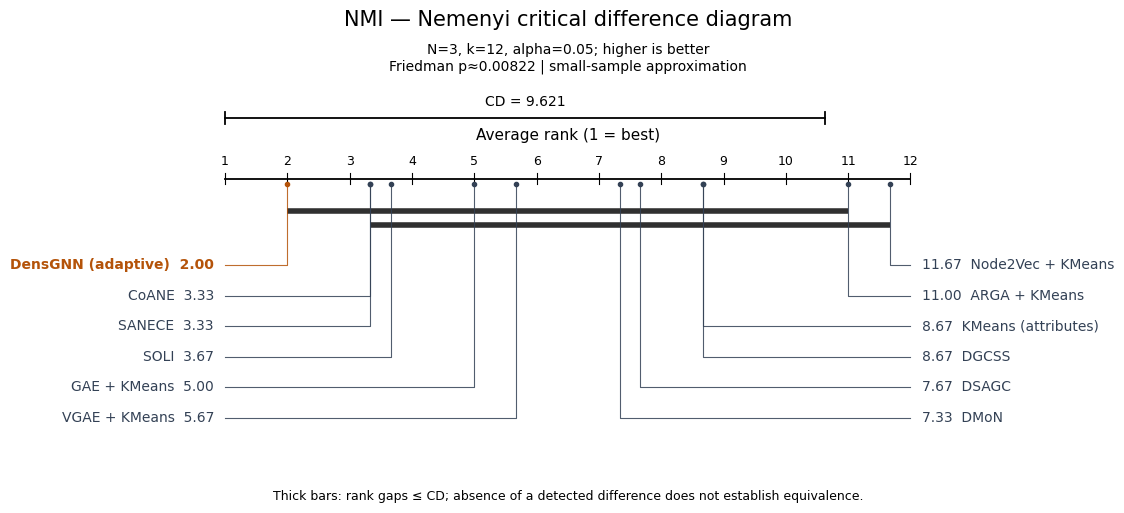

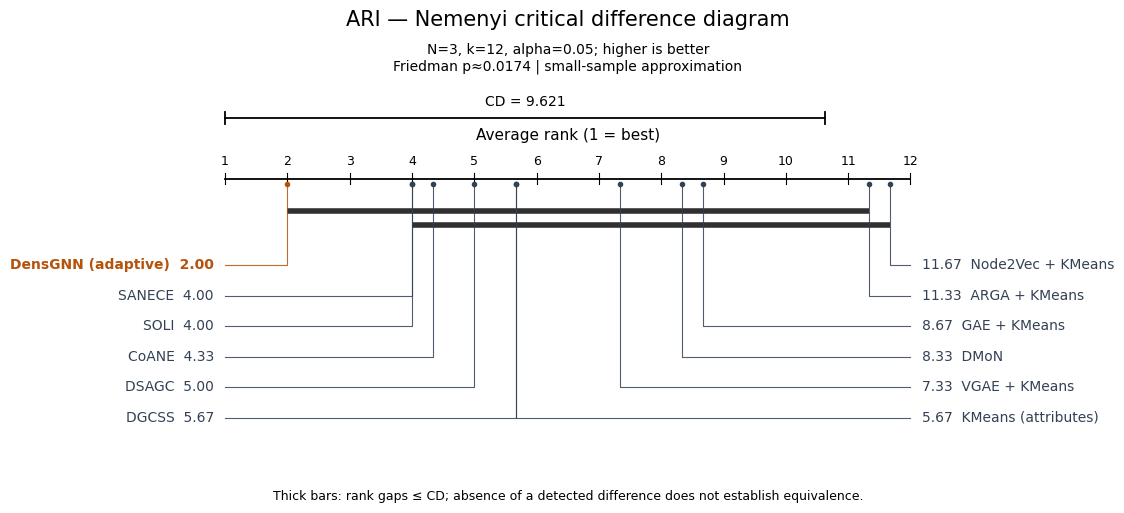

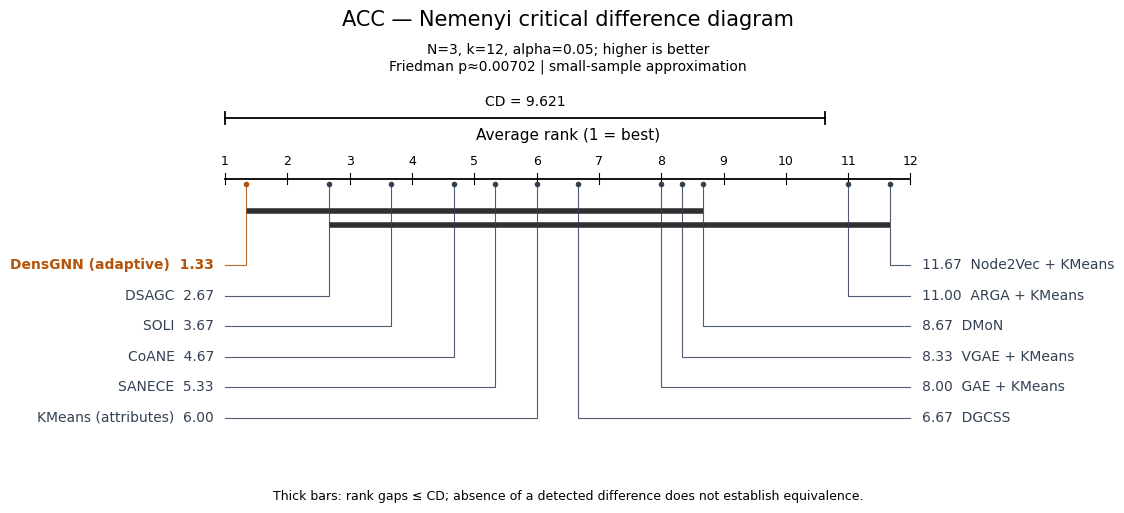

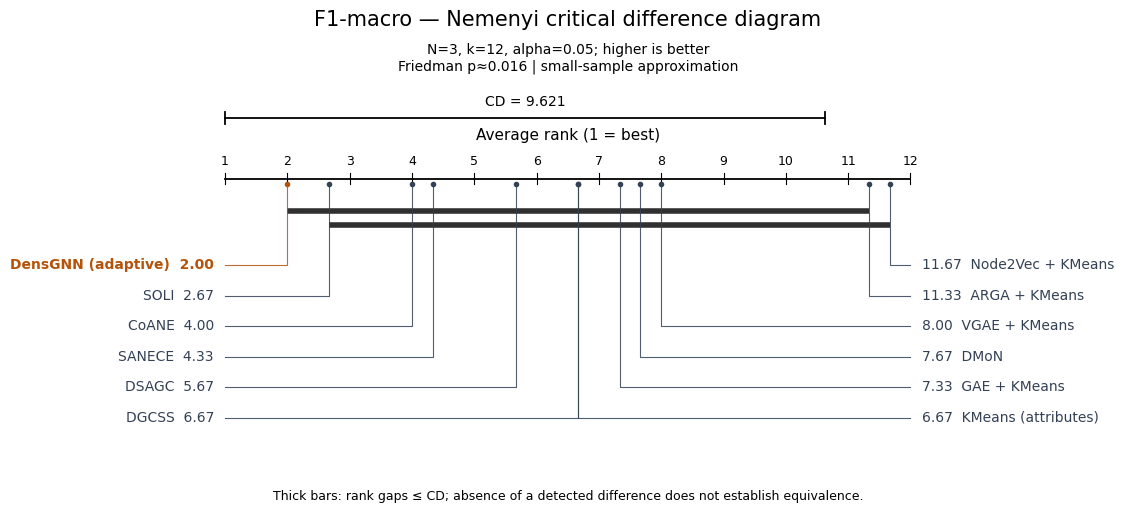

In [12]:
def nonsignificant_intervals(average_ranks, cd):
    values = average_ranks.to_numpy()
    candidates = [(i, j) for i in range(len(values)) for j in range(i + 1, len(values))
                  if values[j] - values[i] <= cd]
    return [(i, j) for i, j in candidates if not any(
        (a, b) != (i, j) and a <= i and j <= b for a, b in candidates
    )]


def plot_cd(result):
    average = result["average_ranks"]
    k = len(average)
    groups = nonsignificant_intervals(average, result["cd"])
    # Separate the group bars from the model labels even when bars overlap.
    group_bottom = 0.45 + 0.19 * max(len(groups) - 1, 0)
    label_top = max(1.0, group_bottom + 0.55)
    rows = (k + 1) // 2
    height = label_top + rows * 0.42 + 0.3
    fig, ax = plt.subplots(figsize=(15, max(5, height)))
    ax.set_xlim(0, k + 1)
    ax.set_ylim(height, -1.15)
    ax.axis("off")
    ax.plot([1, k], [0, 0], color="black", lw=1.3)
    for rank in range(1, k + 1):
        ax.plot([rank, rank], [-0.07, 0.07], color="black", lw=0.8)
        ax.text(rank, -0.14, str(rank), ha="center", va="bottom", fontsize=9)
    ax.text((1 + k) / 2, -0.53, "Average rank (1 = best)", ha="center", fontsize=11)
    if result["cd"] <= k - 1:
        start, end = 1, 1 + result["cd"]
        ax.plot([start, end], [-0.83, -0.83], color="black", lw=1.3)
        ax.plot([start, start], [-0.91, -0.75], color="black", lw=1.3)
        ax.plot([end, end], [-0.91, -0.75], color="black", lw=1.3)
        ax.text((start + end) / 2, -0.96, f"CD = {result['cd']:.3f}", ha="center", va="bottom", fontsize=10)
    else:
        ax.text((1 + k) / 2, -0.96, f"CD = {result['cd']:.3f} > rank range ({k - 1}); no pair exceeds CD",
                ha="center", va="bottom", fontsize=10)
    for row, (i, j) in enumerate(groups):
        y = 0.45 + row * 0.19
        ax.plot([average.iloc[i], average.iloc[j]], [y, y], color="#303030", lw=4, solid_capstyle="butt")
    left = list(average.index[:rows])
    right = list(reversed(average.index[rows:]))
    for side, models in (("left", left), ("right", right)):
        for row, model in enumerate(models):
            y = label_top + row * 0.42
            rank = average[model]
            color = "#b45309" if model == HIGHLIGHT_MODEL else "#334155"
            end = 1 if side == "left" else k
            text_x = end - 0.18 if side == "left" else end + 0.18
            ax.plot([rank, rank, end], [0.08, y, y], color=color, lw=0.8, alpha=0.85)
            ax.plot(rank, 0.08, marker="o", markersize=3, color=color)
            name = MODEL_NAMES.get(model, model)
            label = f"{name}  {rank:.2f}" if side == "left" else f"{rank:.2f}  {name}"
            ax.text(text_x, y, label, ha="right" if side == "left" else "left", va="center",
                    fontsize=10, color=color, weight="bold" if model == HIGHLIGHT_MODEL else "normal")
    metric = result["metric"]
    direction = "higher is better" if METRIC_DIRECTIONS[metric] == "higher" else "lower is better"
    caveat = " | small-sample approximation" if result["small_sample"] else ""
    if not result["friedman_reject"]:
        caveat += " | exploratory: Friedman did not reject"
    fig.suptitle(f"{METRIC_NAMES.get(metric, metric)} — Nemenyi critical difference diagram", y=0.99, fontsize=15)
    ax.set_title(f"N={result['n_datasets']}, k={k}, alpha={ALPHA:g}; {direction}\n"
                 f"Friedman p≈{result['friedman_pvalue']:.3g}{caveat}", fontsize=10, pad=18)
    fig.text(0.5, 0.01, "Thick bars: rank gaps ≤ CD; absence of a detected difference does not establish equivalence.",
             ha="center", fontsize=9)
    fig.subplots_adjust(left=0.23, right=0.77, top=0.82, bottom=0.07)
    return fig


figures = {}
for metric, result in analyses.items():
    if result["status"] != "ok":
        continue
    fig = plot_cd(result)
    figures[metric] = fig
    plt.show()
    plt.close(fig)

## Export figures and audit data

Save PNG, SVG, and PDF versions of each diagram, per-dataset scores and ranks, average ranks, finite run counts, pairwise CD threshold flags, and inclusion/exclusion tables. `analysis_metadata.json` records settings, source files, library versions, and the snapshot time. These files describe the current snapshot and are replaced when rerunning; change `EXPORT_DIR` to keep another snapshot. Original benchmark files are only read.

In [13]:
if SAVE_EXPORTS:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for name, frame in {"source_inventory": inventory, "load_issues": load_issues,
                        "summary": summary, "selected_attempts": selected,
                        "failed_attempts": failed, "discarded_retries": discarded}.items():
        frame.drop(columns=["_row", "_success", "_trial"], errors="ignore").to_csv(EXPORT_DIR / f"{name}.csv", index=False)
    statistics = []
    for metric, result in analyses.items():
        directory = EXPORT_DIR / metric
        directory.mkdir(exist_ok=True)
        result["model_audit"].to_csv(directory / "model_coverage.csv", index=False)
        result["dataset_audit"].to_csv(directory / "dataset_coverage.csv", index=False)
        statistics.append({key: result.get(key) for key in [
            "metric", "status", "n_datasets", "n_models", "cd", "friedman_statistic",
            "friedman_pvalue", "friedman_reject", "small_sample"
        ]})
        # Clear only our own previous exports, including when a metric is now skipped.
        # This prevents old diagrams from appearing to describe the current snapshot.
        for filename in ["scores.csv", "ranks.csv", "run_counts.csv", "average_ranks.csv",
                         "nemenyi_exceeds_cd.csv", "critical_difference.png", "critical_difference.svg", "critical_difference.pdf"]:
            (directory / filename).unlink(missing_ok=True)
        if result["status"] != "ok":
            continue
        for name, frame in {"scores": result["scores"], "ranks": result["ranks"],
                            "run_counts": result["counts"], "average_ranks": result["average_ranks"].rename("average_rank"),
                            "nemenyi_exceeds_cd": result["nemenyi_exceeds_cd"]}.items():
            frame.to_csv(directory / f"{name}.csv")
        for extension in ("png", "svg", "pdf"):
            figures[metric].savefig(directory / f"critical_difference.{extension}", dpi=200, bbox_inches="tight")
    pd.DataFrame(statistics).to_csv(EXPORT_DIR / "statistical_summary.csv", index=False)
    metadata = {
        "snapshot_utc": SNAPSHOT_TIME, "results_root": str(RESULTS_ROOT),
        "result_paths": RESULT_PATHS, "metrics": METRICS, "models": MODELS,
        "model_aliases": MODEL_ALIASES,
        "datasets": DATASETS, "exclude_models": EXCLUDE_MODELS, "source_overrides": SOURCE_OVERRIDES,
        "min_valid_runs": MIN_VALID_RUNS, "min_datasets_per_model": MIN_DATASETS_PER_MODEL,
        "alpha": ALPHA, "metric_directions": {m: METRIC_DIRECTIONS[m] for m in METRICS},
        "method": "Nemenyi all-pairs on per-dataset average ranks; studentized range / sqrt(2)",
        "retry_policy": "latest success per dataset/model/seed; otherwise latest failed attempt",
        "source_files": sorted(raw["metrics_file"].unique().tolist()),
        "versions": {"numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__},
        "comparisons": statistics,
    }
    (EXPORT_DIR / "analysis_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
    print(f"Saved figures, ranks, and audit tables to {EXPORT_DIR}")
else:
    print("Exports disabled (SAVE_EXPORTS=False). Figures remain visible above.")

Saved figures, ranks, and audit tables to /home/gmessias/NodeClusteringAlgorithms/results/critical_difference
